# Case File 01: The Messy Evidence
**Objective 1 · Python, NumPy, Pandas · cleaning, transformation, filtering, aggregation**

**The case.** A city's short-term rental market is described by thousands of listings, but the raw file is a mess:
prices are text with `$` signs, percentages are strings, booleans are `"t"`/`"f"`, and a few listings charge absurd amounts.
Can I turn this into evidence I'd trust?

**The witness.** [Inside Airbnb](http://insideairbnb.com/get-the-data/) detailed listings for one city (`listings.csv.gz`).
Save it as `data/raw/listings.csv.gz`. This run uses Albany, New York. If you pick another city, change `CITY_CENTRE` below, because the distance-from-centre feature depends on it.

**Rule for this notebook:** every time I drop, fill or cap something, I write down *why*, with row counts.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")                       # so we can import from src/
from src.geo import haversine_km            # NumPy haversine, no loops

from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

RAW = Path("../data/raw/listings.csv.gz")
OUT = Path("../data/processed/listings_clean.csv")
CITY_CENTRE = (42.6526, -73.7562)           # downtown Albany, NY; change this if you use another city

if not RAW.exists():
    raise FileNotFoundError(
        "Download the detailed listings.csv.gz for one city from "
        "http://insideairbnb.com/get-the-data/ and save it as data/raw/listings.csv.gz")

sns.set_theme(style="whitegrid", context="notebook")

## 1. Meet the witness
First look: shape, data types, and what a raw row really looks like.

In [2]:
cols = ["id", "host_id", "host_since", "host_is_superhost", "host_response_rate",
        "neighbourhood_cleansed", "latitude", "longitude", "property_type",
        "room_type", "accommodates", "bedrooms", "beds", "price",
        "minimum_nights", "availability_365", "number_of_reviews",
        "review_scores_rating", "instant_bookable"]

df = pd.read_csv(RAW, usecols=cols)
rows_raw = len(df)
print("Raw shape:", df.shape)
df.info()
df.head(3)

Raw shape: (500, 19)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      500 non-null    int64  
 1   host_id                 500 non-null    int64  
 2   host_since              0 non-null      float64
 3   host_response_rate      0 non-null      float64
 4   host_is_superhost       500 non-null    str    
 5   neighbourhood_cleansed  500 non-null    str    
 6   latitude                500 non-null    float64
 7   longitude               500 non-null    float64
 8   property_type           500 non-null    str    
 9   room_type               500 non-null    str    
 10  accommodates            500 non-null    int64  
 11  bedrooms                500 non-null    int64  
 12  beds                    493 non-null    float64
 13  price                   467 non-null    str    
 14  minimum_nights          499 non-

,id,host_id,host_since,host_response_rate,host_is_superhost,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bedrooms,beds,price,minimum_nights,availability_365,number_of_reviews,review_scores_rating,instant_bookable
0,2992450,4621559,NaN,NaN,f,THIRD WARD,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,2,2.0,$65.73,28.0,169,9,3.56,NaN
1,3820211,19648678,NaN,NaN,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1,1.0,$171.00,1.0,342,320,4.75,NaN
2,6623339,19648678,NaN,NaN,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,2,1,1.0,$242.00,1.0,337,344,4.74,NaN


Prices and percentages are strings, and the true/false flags are `t`/`f`. None of that is usable for maths yet.

### Data-quality check: are any columns completely empty?
Some Inside Airbnb files arrive with whole columns blank. A column that is 100% missing can't be cleaned, only noticed, so I check before building anything on it.

In [3]:
empty_cols = [c for c in df.columns if df[c].isna().all()]
print("Completely empty columns in this file:", empty_cols or "none")

Completely empty columns in this file: ['host_since', 'host_response_rate', 'instant_bookable']


## 2. Fix the types

In [4]:
# Prices arrive like "$1,250.00": strip symbols, then convert
df["price"] = pd.to_numeric(
    df["price"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce")

# "98%" -> 0.98
df["host_response_rate"] = pd.to_numeric(
    df["host_response_rate"].astype("string").str.rstrip("%"),
    errors="coerce") / 100

# "t"/"f" -> 1/0 (NaN stays NaN, so I can decide how to treat unknowns later)
for col in ["host_is_superhost", "instant_bookable"]:
    df[col] = df[col].map({"t": 1, "f": 0})

df["host_since"] = pd.to_datetime(df["host_since"], errors="coerce")
df[["price", "host_response_rate", "host_is_superhost", "host_since"]].dtypes

price                       Float64
host_response_rate          Float64
host_is_superhost             int64
host_since            datetime64[s]
dtype: object

## 3. Missing values: decide column by column

host_since              1.000
instant_bookable        1.000
host_response_rate      1.000
review_scores_rating    0.102
price                   0.066
beds                    0.014
minimum_nights          0.002
dtype: float64


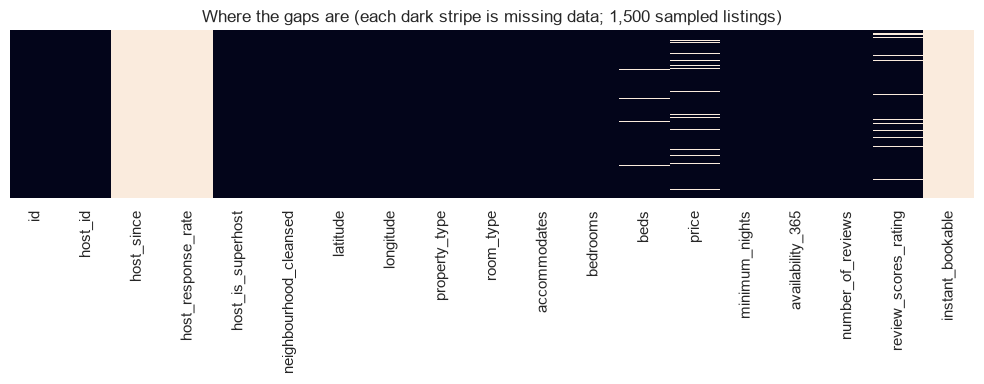

In [5]:
missing = df.isna().mean().sort_values(ascending=False)
print(missing[missing > 0].round(3))

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(df.sample(min(len(df), 1500), random_state=42).isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Where the gaps are (each dark stripe is missing data; 1,500 sampled listings)")
plt.tight_layout()
plt.savefig(FIG / "01_missing_values.png", dpi=200)
plt.show()

My decisions, one per column:

| Column | Decision | Why |
|---|---|---|
| `price` | drop rows with no price | no price means no use for pricing analysis |
| `review_scores_rating` | keep NaN, add a `has_reviews` flag | "never reviewed" is a signal, not just a gap |
| `bedrooms` | fill with the median of the same room type | a studio and a 3-bed house shouldn't share a median |
| `beds` | fill with `accommodates / 2`, rounded | simple, documented assumption |

In [6]:
before = len(df)
df = df.dropna(subset=["price"])
print(f"Dropped {before - len(df):,} rows with no price")

df["has_reviews"] = df["review_scores_rating"].notna().astype(int)
df["bedrooms"] = df["bedrooms"].fillna(df.groupby("room_type")["bedrooms"].transform("median"))
df["beds"] = df["beds"].fillna(df["accommodates"] / 2).round()

Dropped 33 rows with no price


## 4. Tame outliers: cap, don't silently delete
I keep prices between the 1st and 99th percentile (with a floor of 10), and I record how many rows that costs.

In [7]:
low, high = df["price"].quantile([0.01, 0.99])
print(f"Keeping prices between {max(low, 10):.0f} and {high:.0f}")
before = len(df)
df = df[df["price"].between(max(low, 10), high)].copy()
print(f"Removed {before - len(df):,} outlier rows ({(before - len(df)) / before:.1%})")

Keeping prices between 37 and 4823
Removed 10 outlier rows (2.1%)


## 5. Engineer features
Distance to the city centre uses the NumPy haversine helper from `src/geo.py`. It works on whole columns at once, with no Python loop.

In [8]:
df["dist_centre_km"] = haversine_km(df["latitude"], df["longitude"], *CITY_CENTRE)
# Sanity check: if this fails, CITY_CENTRE doesn't match the city in your file
assert df["dist_centre_km"].median() < 50, (
    f"Median distance is {df['dist_centre_km'].median():,.0f} km. "
    "CITY_CENTRE is probably set for a different city; update it in the first code cell.")

# host_since can be empty in some files; only build tenure if there is data to build it from
if df["host_since"].notna().any():
    df["host_tenure_years"] = (pd.Timestamp.today() - df["host_since"]).dt.days / 365.25
else:
    print("host_since is empty in this file, so host_tenure_years is skipped.")
df["price_per_guest"] = df["price"] / df["accommodates"].clip(lower=1)

new_features = [c for c in ["dist_centre_km", "host_tenure_years", "price_per_guest"] if c in df.columns]
df[new_features].describe().round(2)

host_since is empty in this file, so host_tenure_years is skipped.


,dist_centre_km,price_per_guest
count,457.00,457.0
mean,2.26,56.39
std,1.43,26.48
min,0.32,8.6
25%,0.92,38.22
50%,2.05,52.33
75%,3.35,71.5
max,6.52,277.5


## 6. Filtering and aggregation

In [9]:
# Filtering: larger entire homes
entire_homes = df.query("room_type == 'Entire home/apt' and accommodates >= 4")
print(f"Entire homes for 4+ guests: {len(entire_homes):,} ({len(entire_homes)/len(df):.1%} of listings)")

# Aggregation: neighbourhood summary (only neighbourhoods with 30+ listings)
summary = (df.groupby("neighbourhood_cleansed")
             .agg(listings=("id", "count"),
                  median_price=("price", "median"),
                  avg_rating=("review_scores_rating", "mean"),
                  superhost_share=("host_is_superhost", "mean"))
             .query("listings >= 30")
             .sort_values("median_price", ascending=False))
summary.head(10).round(2)

Entire homes for 4+ guests: 184 (40.3% of listings)


,listings,median_price,avg_rating,superhost_share
neighbourhood_cleansed,,,,
SECOND WARD,42,188.25,4.73,0.45
SIXTH WARD,105,153.0,4.74,0.49
NINTH WARD,43,129.0,4.81,0.58
THIRTEENTH WARD,41,115.0,4.89,0.73
FOURTEENTH WARD,32,107.17,4.89,0.66
TENTH WARD,48,103.5,4.81,0.44
ELEVENTH WARD,38,98.1,4.21,0.08


In [10]:
# Room-type summary
(df.groupby("room_type")
   .agg(listings=("id", "count"), median_price=("price", "median"), median_guests=("accommodates", "median"))
   .sort_values("listings", ascending=False).round(1))

,listings,median_price,median_guests
room_type,,,
Entire home/apt,327,167.0,4.0
Private room,129,76.0,1.0
Shared room,1,840.0,15.0


## 7. Save the clean file and keep the receipts

In [11]:
OUT.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT, index=False)

print(f"Rows: {rows_raw:,} raw -> {len(df):,} clean ({len(df)/rows_raw:.1%} kept)")
print(f"Saved {OUT}")

Rows: 500 raw -> 457 clean (91.4% kept)
Saved ..\data\processed\listings_clean.csv


### Case closed
What I removed, what I filled, and why (500 → 457 rows, 91.4% kept):

| Step | Rows affected | Reason |
|---|---|---|
| Dropped: no price | 33 | No price means no use for pricing analysis |
| Dropped: price outside the 1st–99th percentile ($37 to $4,823) | 10 (2.1%) | Extreme listings would dominate averages and the model |
| Filled: `bedrooms` | 0 | None were missing in this file; the median-by-room-type rule is there for other cities |
| Filled: `beds` | up to 7 | Used `accommodates / 2`, rounded |
| Skipped: `host_tenure_years` | all rows | `host_since` is completely empty in this city's file |

**Lesson:** I first left `CITY_CENTRE` set to Amsterdam, which produced "distances" of about 5,700 km. The notebook now stops with a clear message if the median distance looks wrong.